# Latent Feature Extraction for Musical Genres from Raw Audio — all 10 GTZAN genres

This notebook has two parts:
- **Part 1 — Paper models on all 10 genres.** The models from Sawhney, Vasavada & Wang, *Latent Feature Extraction for
  Musical Genres from Raw Audio* ([references/musical_genre.pdf](references/musical_genre.pdf)). It retains the
  three architectures and training settings, with 10 classifier outputs and the full dataset.
- **Part 2 — Improving on the paper.** The existing improved models, now trained on all 10 genres, evaluated with a shared protocol,
  and one comparison table for all models.

---
# Part 1 — Paper models on the full GTZAN dataset

**Scope of this run.** All 1,000 songs in all 10 genres are used. Every classifier now outputs 10 logits;
hidden layers, activations, bottleneck sizes, losses and training schedules are unchanged. The clip split keeps
the original 75% / 12.5% / 12.5% proportions. The paper's published four-genre scores remain historical reference
only; they are not directly comparable with this harder ten-class task.

**Rule for the inherited settings.** The paper text comes first. Where the paper does not give a value, the notebook uses
the authors' linked code (paper p.6: `github.com/arjunsawknee/Genre-Extraction`, commit `00b1802`).
When the two disagree, the paper wins. The table below gives the source of every setting.

| Setting | Value used | Source |
|---|---|---|
| Genres | blues, classical, country, disco, hiphop, jazz, metal, pop, reggae, rock | Full GTZAN extension |
| Audio loading | convert to `.wav`, load with LibROSA at the native 22.05 kHz | Paper §3 |
| Segment length | 20,000 samples | Paper §3 ("each of the original samples was in R^20,000") |
| Segments per song | 20 consecutive segments from the start of each song → 1,000 × 20 = 20,000 examples | Same 20 segments per song as paper/code; expanded to all songs |
| Downsampling | average pooling, pool size 40 → R^500 | Paper §3, Fig. 2 |
| Feature engineering / normalisation | none | Paper §3 |
| Split | random 15,000 / 2,500 / 2,500 (train / dev / test) | Same proportions as Paper §3, Table 1 |
| Two-layer NN | 500 → 128 (tanh) → 10, softmax cross-entropy (Eq. 1) | Paper §4.1; output expanded to 10 |
| Autoencoder widths | 500→256→192→128→**64**→128→192→256→500 | Paper Fig. 2 |
| Classifier head | 64→32→16→10 | Paper Fig. 2; output expanded to 10 |
| Vanilla AE loss | ‖x − g(f(x))‖²₂ (Eq. 2) | Paper §4.2 |
| Deep Softmax AE loss | γ‖x − g(f(x))‖²₂ − (1−γ) Σ yᵢ log ŷᵢ, γ = 0.9 (Eq. 3) | Paper §4.3 |
| Optimiser | Adam, learning rate 0.0001, batch size 512 | Paper Fig. 2 |
| Dropout | keep probability 0.9 (dropout rate 0.1) | Paper §5.1 |
| Dropout position | after the 192-unit layer in the encoder and in the decoder | Code (paper: "between layers", no position) |
| AE activations | encoder sigmoid, tanh, ReLU, ReLU; decoder sigmoid, sigmoid, ReLU, ReLU | Code (paper gives none) |
| Head activations | tanh, tanh, then linear logits → softmax | Code (paper gives none) |
| Initialisation | Xavier (Glorot) uniform weights, zero biases | Code |
| Epochs | Deep Softmax AE 500 (Fig. 3 x-axis); two-layer NN 200; vanilla AE 400 | Paper Fig. 3; code for the other two |
| Batching | training set shuffled once, then the same batch order every epoch; last short batch kept | Code |
| Model evaluated | the model after the final epoch (no early stopping) | Code (paper describes none) |
| Batch loss | mean of the per-example loss over the batch | Code (`reduce_mean`) |
| PCA | 2 components, fitted on all 20,000 examples | Same PCA method; all ten genres |

The paper and the code disagree on three settings. The paper value is used for all three:
- **Loss weight:** code uses `mean-over-500 MSE + 0.1·CE`; the paper's Eq. 3 uses `0.9·squared-L2 + 0.1·CE`.
- **Keep probability:** code uses 0.8; the paper uses 0.9.
- **Joint epochs:** code uses 200; the paper's Fig. 3 runs to about 500.

The paper writes Eq. 3 as `γ‖·‖² − (1−γ)Σ y log ŷ`. Because `−Σ y log ŷ` is the cross-entropy, this is
`0.9·reconstruction + 0.1·cross-entropy`.

Two things are not given by either source, so they are fixed here: a random seed (`SEED = 0`) and the GTZAN copy.
The original download link is offline, so the notebook uses a complete mirror of the same 1,000 `.au` files.

**On "one second":** the paper says "one second segments" but also says each segment is in R^20,000, and that
20,000 samples pool to 500 values. At 22,050 Hz, 20,000 samples last less than one second (the data cell prints the exact length). The paper's segment dimensions (20,000 → 500) are kept; all 1,000 songs yield 20,000 examples.

In [1]:
from pathlib import Path
import hashlib, json, random, tarfile, time, urllib.request
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

ROOT = Path.cwd()
SEED = 0
GENRES = ["blues", "classical", "country", "disco", "hiphop",
          "jazz", "metal", "pop", "reggae", "rock"]       # label index = position
N_CLASSES = len(GENRES)
SONGS_PER_GENRE = 100
DATASET_ID = "gtzan_10_genres"
SAMPLE_RATE = 22050                                      # paper §3: native 22.05 kHz
SEGMENT_SAMPLES = 20000                                  # paper §3: R^20,000
SEGMENTS_PER_SONG = 20                                   # 1,000 songs x 20 = 20,000 examples
POOL_SIZE = 40                                           # paper §3: pool size 40 -> R^500
N_EXAMPLES = N_CLASSES * SONGS_PER_GENRE * SEGMENTS_PER_SONG
SPLIT_SIZES = (N_EXAMPLES * 3 // 4, N_EXAMPLES // 8, N_EXAMPLES // 8)  # 75% / 12.5% / 12.5%
CODE_SPLIT_SIZES = (SPLIT_SIZES[0], sum(SPLIT_SIZES[1:]), 0)           # 75% / 25%, appendix
LEARNING_RATE = 1e-4                                     # paper Fig. 2
BATCH_SIZE = 512                                         # paper Fig. 2
KEEP_PROB = 0.9                                          # paper §5.1
GAMMA = 0.9                                              # paper §4.3
EPOCHS = {"two_layer_nn": 200, "vanilla_ae": 400, "deep_softmax_ae": 500}

AU_ROOT = ROOT / "data/raw/gtzan_qiuqiangkong/genres"    # original GTZAN .au files
WAV_ROOT = ROOT / "data/interim/gtzan_wav"               # paper §3: converted to .wav
OUT = ROOT / "artifacts/paper_reproduction" / DATASET_ID
OUT.mkdir(parents=True, exist_ok=True)
ARCHIVE = ROOT / "data/downloads/genres-qiuqiangkong.tar.gz"
ARCHIVE_URL = ("https://huggingface.co/datasets/qiuqiangkong/gtzan/resolve/"
               "9df3f542ce11be457c4d4eeb81d9755349f72012/genres.tar.gz?download=true")
ARCHIVE_SHA256 = "74a8901dfdd256ac13cc6cd529f36aaa156a4d304447f970c4dc87d7cb3fd957"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything(SEED)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")
print("librosa", librosa.__version__, "| torch", torch.__version__)

librosa 1.0.0 | torch 2.14.1


## 3. Dataset and features

GTZAN has 1,000 thirty-second tracks in 10 genres, and this notebook uses every genre and every track.
If the audio is not on disk, the next cell downloads and checks the archive, then extracts all ten genres.
It converts each file to `.wav` and loads the amplitudes with LibROSA (`librosa.load`, default 22,050 Hz, mono).

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

if not all((AU_ROOT / g / f"{g}.{i:05d}.au").exists() for g in GENRES for i in range(SONGS_PER_GENRE)):
    if not ARCHIVE.exists():
        ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
        print("Downloading GTZAN (~1.2 GB) ...")
        urllib.request.urlretrieve(ARCHIVE_URL, ARCHIVE)
    assert sha256(ARCHIVE) == ARCHIVE_SHA256, "Archive checksum mismatch"
    with tarfile.open(ARCHIVE) as tar:
        members = [m for m in tar.getmembers() if m.isfile() and m.name.endswith(".au")
                   and Path(m.name).parent.name in GENRES]
        tar.extractall(AU_ROOT.parent, members=members, filter="data")

# Paper §3: "we converted these files into .wav format"
for g in GENRES:
    (WAV_ROOT / g).mkdir(parents=True, exist_ok=True)
    for i in range(SONGS_PER_GENRE):
        src, dst = AU_ROOT / g / f"{g}.{i:05d}.au", WAV_ROOT / g / f"{g}.{i:05d}.wav"
        if not dst.exists():
            audio, sr = sf.read(src, dtype="int16")
            sf.write(dst, audio, sr, subtype="PCM_16")

# Paper §3: "used the Python library LibROSA to convert the audio files to a raw audio time series"
songs = []
for label, g in enumerate(GENRES):
    for i in range(SONGS_PER_GENRE):
        audio, sr = librosa.load(WAV_ROOT / g / f"{g}.{i:05d}.wav")
        assert sr == SAMPLE_RATE and audio.ndim == 1
        songs.append({"song": f"{g}.{i:05d}", "genre": g, "label": label, "audio": audio})
assert len(songs) == N_CLASSES * SONGS_PER_GENRE
print(len(songs), "songs loaded across", N_CLASSES, "genres;",
      "durations %.2f–%.2f s" % (min(len(s["audio"]) for s in songs) / SAMPLE_RATE,
                                 max(len(s["audio"]) for s in songs) / SAMPLE_RATE))

1000 songs loaded across 10 genres; durations 29.93–30.65 s


Each song is cut into 20 consecutive 20,000-sample segments. Each segment is average-pooled with
non-overlapping windows of 40 samples, giving a vector in R^500. The result is 20,000 examples, 2,000 per genre.
The data is not normalised (paper §3: no feature engineering).

In [3]:
X_list, y_list, meta = [], [], []
for s in songs:
    assert len(s["audio"]) >= SEGMENTS_PER_SONG * SEGMENT_SAMPLES
    for j in range(SEGMENTS_PER_SONG):
        segment = s["audio"][j * SEGMENT_SAMPLES:(j + 1) * SEGMENT_SAMPLES]          # R^20,000
        X_list.append(segment.reshape(-1, POOL_SIZE).mean(axis=1))                    # R^500
        y_list.append(s["label"])
        meta.append({"song": s["song"], "genre": s["genre"], "segment": j})
X = np.stack(X_list).astype(np.float32)
y = np.array(y_list, dtype=np.int64)
meta = pd.DataFrame(meta)
assert X.shape == (N_EXAMPLES, SEGMENT_SAMPLES // POOL_SIZE) and np.isfinite(X).all()
assert np.bincount(y, minlength=N_CLASSES).tolist() == [SONGS_PER_GENRE * SEGMENTS_PER_SONG] * N_CLASSES
print("X", X.shape, "| y counts", dict(zip(GENRES, np.bincount(y))))
print(f"segment length: {SEGMENT_SAMPLES} samples = {SEGMENT_SAMPLES / SAMPLE_RATE:.3f} s at {SAMPLE_RATE} Hz")

# Same clip-split proportions as the paper, scaled to all ten genres
def random_split(seed, sizes=SPLIT_SIZES):
    assert len(sizes) == 3 and sum(sizes) == len(X) and min(sizes) >= 0
    perm = np.random.default_rng(seed).permutation(len(X))
    n_train, n_dev = sizes[0], sizes[1]
    return {"train": perm[:n_train], "dev": perm[n_train:n_train + n_dev], "test": perm[n_train + n_dev:]}

split = random_split(SEED)
np.savez(OUT / "split_indices.npz", **split)
for name, idx in split.items():
    print(f"{name:5s} {len(idx):5d}", dict(zip(GENRES, np.bincount(y[idx], minlength=N_CLASSES))))

X (20000, 500) | y counts {'blues': np.int64(2000), 'classical': np.int64(2000), 'country': np.int64(2000), 'disco': np.int64(2000), 'hiphop': np.int64(2000), 'jazz': np.int64(2000), 'metal': np.int64(2000), 'pop': np.int64(2000), 'reggae': np.int64(2000), 'rock': np.int64(2000)}
segment length: 20000 samples = 0.907 s at 22050 Hz
train 15000 {'blues': np.int64(1476), 'classical': np.int64(1518), 'country': np.int64(1534), 'disco': np.int64(1491), 'hiphop': np.int64(1489), 'jazz': np.int64(1493), 'metal': np.int64(1535), 'pop': np.int64(1489), 'reggae': np.int64(1475), 'rock': np.int64(1500)}
dev    2500 {'blues': np.int64(246), 'classical': np.int64(242), 'country': np.int64(238), 'disco': np.int64(268), 'hiphop': np.int64(259), 'jazz': np.int64(247), 'metal': np.int64(242), 'pop': np.int64(256), 'reggae': np.int64(238), 'rock': np.int64(264)}
test   2500 {'blues': np.int64(278), 'classical': np.int64(240), 'country': np.int64(228), 'disco': np.int64(241), 'hiphop': np.int64(252), 'ja

### PCA plotting helper

`pca_plot` projects any set of vectors to 2 dimensions with PCA and colours the points by genre, using the
ten distinct colours. It is used for Figure 5 and for the best model in Part 2.

In [4]:
PCA_COLORS = [(plt.get_cmap("tab10")(i), genre.capitalize(), i) for i, genre in enumerate(GENRES)]

def pca_plot(ax, data, labels, title):
    points = PCA(n_components=2).fit_transform(data)
    for color, name, label in PCA_COLORS:
        ax.scatter(points[labels == label, 0], points[labels == label, 1], color=color,
                   alpha=.5, label=name, edgecolor="k", s=14, linewidths=.3)
    ax.set_title(title); ax.legend(loc="upper right", fontsize=8, ncol=2)

## 4. Models and method

### 4.1 Two-layer neural network (baseline)
500 → 128 (tanh) → 10. The loss is the softmax cross-entropy, Eq. 1: L = −Σⱼ yⱼ log ŷⱼ.

### 4.2 Vanilla autoencoder
The encoder f maps R^500 → R^64 and the decoder g maps R^64 → R^500, using the top half of Fig. 2.
The loss is Eq. 2: L = ‖x − g(f(x))‖²₂, summed over the 500 values of each example.

### 4.3 Deep Softmax Autoencoder
The same autoencoder, plus a classifier 64 → 32 → 16 → 10 that takes the 64-dimensional encoding as input.
The loss is Eq. 3 with γ = 0.9.

All weights use Xavier initialisation and zero biases. Dropout has keep probability 0.9.

In [5]:
def xavier(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight); nn.init.zeros_(module.bias)

DROPOUT = 1 - KEEP_PROB

class TwoLayerNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(500, 128), nn.Tanh(), nn.Linear(128, N_CLASSES))
        self.apply(xavier)
    def forward(self, x):
        return {"logits": self.net(x)}

class Encoder(nn.Module):          # f : R^500 -> R^64
    def __init__(self, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(500, 256), nn.Sigmoid(),
                                 nn.Linear(256, 192), nn.Tanh(), nn.Dropout(dropout),
                                 nn.Linear(192, 128), nn.ReLU(),
                                 nn.Linear(128, 64), nn.ReLU())
    def forward(self, x):
        return self.net(x)

class Decoder(nn.Module):          # g : R^64 -> R^500
    def __init__(self, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 128), nn.Sigmoid(),
                                 nn.Linear(128, 192), nn.Sigmoid(), nn.Dropout(dropout),
                                 nn.Linear(192, 256), nn.ReLU(),
                                 nn.Linear(256, 500), nn.ReLU())
    def forward(self, z):
        return self.net(z)

class VanillaAutoencoder(nn.Module):
    def __init__(self, dropout=DROPOUT):
        super().__init__()
        self.encoder, self.decoder = Encoder(dropout), Decoder(dropout)
        self.apply(xavier)
    def forward(self, x):
        z = self.encoder(x)
        return {"encoding": z, "reconstruction": self.decoder(z)}

class DeepSoftmaxAutoencoder(nn.Module):
    def __init__(self, dropout=DROPOUT):
        super().__init__()
        self.encoder, self.decoder = Encoder(dropout), Decoder(dropout)
        self.classifier = nn.Sequential(nn.Linear(64, 32), nn.Tanh(),
                                        nn.Linear(32, 16), nn.Tanh(),
                                        nn.Linear(16, N_CLASSES))          # logits; softmax inside the loss
        self.apply(xavier)
    def forward(self, x):
        z = self.encoder(x)
        return {"encoding": z, "reconstruction": self.decoder(z), "logits": self.classifier(z)}

def cross_entropy(out, x, t):                    # Eq. 1, mean over the batch
    return nn.functional.cross_entropy(out["logits"], t)

def reconstruction(out, x, t):                   # Eq. 2, ||x - g(f(x))||_2^2, mean over the batch
    return (x - out["reconstruction"]).pow(2).sum(dim=1).mean()

def deep_softmax_loss(out, x, t):                # Eq. 3 with gamma = 0.9
    return GAMMA * reconstruction(out, x, t) + (1 - GAMMA) * cross_entropy(out, x, t)

for model in [TwoLayerNN(), VanillaAutoencoder(), DeepSoftmaxAutoencoder()]:
    print(type(model).__name__, sum(p.numel() for p in model.parameters()), "parameters")

TwoLayerNN 65418 parameters
VanillaAutoencoder 421556 parameters
DeepSoftmaxAutoencoder 424334 parameters


### Training

Adam with learning rate 0.0001 and batch size 512. As in the authors' code, the 15,000 training examples are
shuffled once and the batches keep the same order every epoch. Each epoch logs:
- train loss and running train accuracy, measured during the updates with dropout on (as plotted in Fig. 3);
- dev accuracy and dev loss, measured with dropout off.

The model after the last epoch is the one evaluated.

In [6]:
X_t, y_t = torch.from_numpy(X), torch.from_numpy(y)

def predict(model, idx):
    model.eval()
    with torch.no_grad():
        return model(X_t[idx].to(DEVICE))

def train(name, model_class, loss_fn, epochs, seed=SEED, data_split=None, save=True):
    data_split = split if data_split is None else data_split
    seed_everything(seed)
    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    order = data_split["train"][np.random.default_rng(seed).permutation(len(data_split["train"]))]  # shuffled once
    batches = [order[i:i + BATCH_SIZE] for i in range(0, len(order), BATCH_SIZE)]
    history, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        losses, correct = [], 0
        for b in batches:
            xb, tb = X_t[b].to(DEVICE), y_t[b].to(DEVICE)
            out = model(xb)
            loss = loss_fn(out, xb, tb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(loss.item())
            if "logits" in out:
                correct += (out["logits"].argmax(1) == tb).sum().item()
        row = {"epoch": epoch, "train_loss": float(np.mean(losses))}
        dev = data_split["dev"]
        dev_out = predict(model, dev)
        row["dev_loss"] = loss_fn(dev_out, X_t[dev], y_t[dev]).item()
        if "logits" in dev_out:
            row["train_accuracy"] = correct / len(order)
            row["dev_accuracy"] = (dev_out["logits"].argmax(1) == y_t[dev]).float().mean().item()
        history.append(row)
        if save and (epoch % 50 == 0 or epoch == epochs):
            print(f"{name} epoch {epoch:3d}: " + ", ".join(f"{k}={v:.4f}" for k, v in row.items() if k != "epoch"))
    history = pd.DataFrame(history)
    if save:
        print(f"{name}: {time.time() - start:.0f} s")
        history.to_csv(OUT / f"{name}_history.csv", index=False)
        torch.save(model.state_dict(), OUT / f"{name}.pt")
    return model, history

In [7]:
two_layer_nn, nn_history = train("two_layer_nn", TwoLayerNN, cross_entropy, EPOCHS["two_layer_nn"])

two_layer_nn epoch  50: train_loss=2.2068, dev_loss=2.3335, train_accuracy=0.2543, dev_accuracy=0.1692


two_layer_nn epoch 100: train_loss=2.1646, dev_loss=2.3686, train_accuracy=0.2736, dev_accuracy=0.1752


two_layer_nn epoch 150: train_loss=2.1435, dev_loss=2.3928, train_accuracy=0.2796, dev_accuracy=0.1824


two_layer_nn epoch 200: train_loss=2.1314, dev_loss=2.4085, train_accuracy=0.2831, dev_accuracy=0.1820
two_layer_nn: 4 s


In [8]:
vanilla_ae, ae_history = train("vanilla_ae", VanillaAutoencoder, reconstruction, EPOCHS["vanilla_ae"])

vanilla_ae epoch  50: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 100: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 150: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 200: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 250: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 300: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 350: train_loss=6.1742, dev_loss=6.3413


vanilla_ae epoch 400: train_loss=6.1742, dev_loss=6.3413
vanilla_ae: 36 s


**Reconstruction check.** The decoder's last activation is a ReLU, as in the authors' code, so it can never output
the negative half of a waveform. The next cell measures how many reconstruction values are above zero. If none are,
the output layer has died: the decoder outputs 0 for every input and Eq. 2 stays at Σx², the mean energy of the
input. The cell also prints the mean-over-500 MSE, the loss unit used in the authors' code. This notebook keeps the
architecture unchanged.

In [9]:
recon = predict(vanilla_ae, split["dev"])["reconstruction"]
print("fraction of reconstruction values > 0:", (recon > 0).float().mean().item())
print("dev Eq. 2 loss:", ae_history.dev_loss.iloc[-1], "| dev mean sum(x^2):", X[split["dev"]].__pow__(2).sum(1).mean())
print("dev mean-over-500 MSE:", ae_history.dev_loss.iloc[-1] / X.shape[1])

fraction of reconstruction values > 0: 0.0
dev Eq. 2 loss: 6.341341972351074 | dev mean sum(x^2): 6.341342
dev mean-over-500 MSE: 0.012682683944702148


In [10]:
deep_softmax_ae, dsae_history = train("deep_softmax_ae", DeepSoftmaxAutoencoder, deep_softmax_loss,
                                      EPOCHS["deep_softmax_ae"])

deep_softmax_ae epoch  50: train_loss=5.7849, dev_loss=5.9372, train_accuracy=0.1359, dev_accuracy=0.1348


deep_softmax_ae epoch 100: train_loss=5.7501, dev_loss=5.9156, train_accuracy=0.3025, dev_accuracy=0.2180


deep_softmax_ae epoch 150: train_loss=5.7319, dev_loss=5.9119, train_accuracy=0.3749, dev_accuracy=0.2484


deep_softmax_ae epoch 200: train_loss=5.7171, dev_loss=5.9135, train_accuracy=0.4373, dev_accuracy=0.2648


deep_softmax_ae epoch 250: train_loss=5.7023, dev_loss=5.9208, train_accuracy=0.4931, dev_accuracy=0.2704


deep_softmax_ae epoch 300: train_loss=5.6869, dev_loss=5.9297, train_accuracy=0.5538, dev_accuracy=0.2640


deep_softmax_ae epoch 350: train_loss=5.6732, dev_loss=5.9448, train_accuracy=0.6075, dev_accuracy=0.2764


deep_softmax_ae epoch 400: train_loss=5.6624, dev_loss=5.9619, train_accuracy=0.6469, dev_accuracy=0.2704


deep_softmax_ae epoch 450: train_loss=5.6515, dev_loss=5.9757, train_accuracy=0.6845, dev_accuracy=0.2844


deep_softmax_ae epoch 500: train_loss=5.6450, dev_loss=5.9920, train_accuracy=0.7046, dev_accuracy=0.2800
deep_softmax_ae: 208 s


## 5. Results and discussion

### 5.1 Quantitative analysis

**Figure 3:** Deep Softmax Autoencoder train and dev accuracy for each epoch.

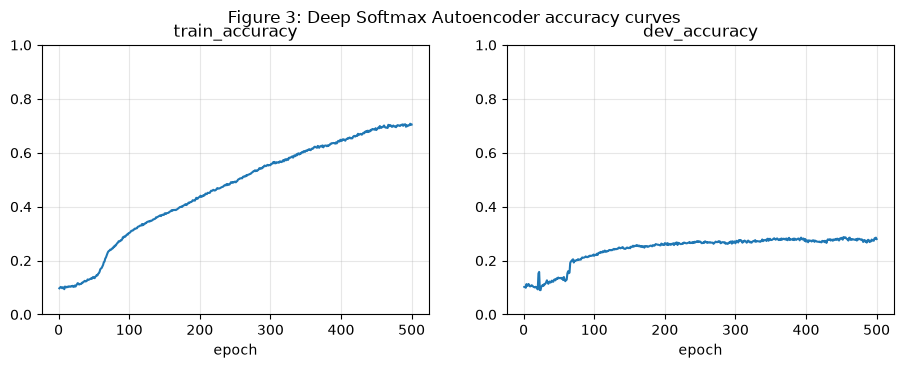

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, column in zip(axes, ["train_accuracy", "dev_accuracy"]):
    ax.plot(dsae_history.epoch, dsae_history[column])
    ax.set(title=column, xlabel="epoch", ylim=(0, 1)); ax.grid(alpha=.3)
fig.suptitle("Figure 3: Deep Softmax Autoencoder accuracy curves")
fig.savefig(OUT / "figure3_accuracy_curves.png", dpi=150, bbox_inches="tight"); plt.show()

**Table 1:** classification accuracy of the final models on each split, with dropout off.

In [12]:
def accuracy(model, idx):
    return (predict(model, idx)["logits"].argmax(1) == y_t[idx]).float().mean().item()

table1 = pd.DataFrame({f"{s.capitalize()} Set ({len(split[s])} Examples)":
                       [accuracy(two_layer_nn, split[s]), accuracy(deep_softmax_ae, split[s])]
                       for s in ["train", "dev", "test"]},
                      index=["Two Layer Neural Network", "Deep Softmax Autoencoder"])
display(table1.style.format("{:.1%}"))

,Train Set (15000 Examples),Dev Set (2500 Examples),Test Set (2500 Examples)
Two Layer Neural Network,28.4%,18.2%,17.5%
Deep Softmax Autoencoder,73.5%,28.0%,28.5%


**Table 2:** precision, recall and F1 for each genre on the 2,500 held-out test examples (Deep Softmax Autoencoder).

In [13]:
test_pred = predict(deep_softmax_ae, split["test"])["logits"].argmax(1).numpy()
test_true = y[split["test"]]
p, r, f, _ = precision_recall_fscore_support(test_true, test_pred, labels=range(N_CLASSES), zero_division=0)
table2 = pd.DataFrame({"Precision": p, "Recall": r, "F1 Score": f}, index=[g.capitalize() for g in GENRES])
display(table2.round(3))

,Precision,Recall,F1 Score
Blues,0.257,0.201,0.226
Classical,0.599,0.746,0.664
Country,0.164,0.154,0.159
Disco,0.231,0.199,0.214
Hiphop,0.240,0.282,0.259
Jazz,0.413,0.446,0.429
Metal,0.187,0.224,0.204
Pop,0.302,0.278,0.290
Reggae,0.233,0.174,0.199
Rock,0.138,0.157,0.147


**Figure 4:** confusion matrix of the Deep Softmax Autoencoder on the 2,500 test examples, normalised by row (true label).

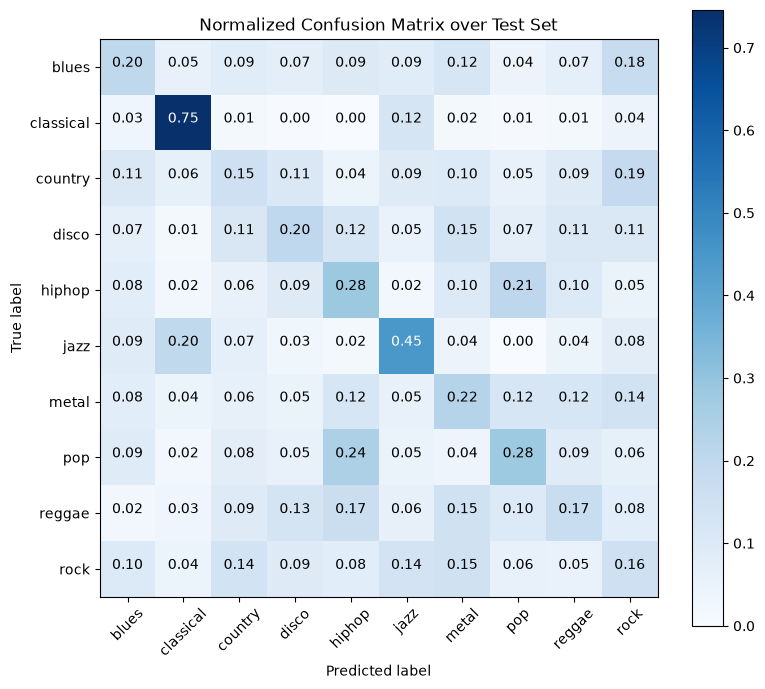

In [14]:
cm = confusion_matrix(test_true, test_pred, labels=range(N_CLASSES)).astype(float)
cm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap=plt.cm.Blues); fig.colorbar(im, ax=ax)
ax.set(xticks=range(N_CLASSES), yticks=range(N_CLASSES), xticklabels=GENRES, yticklabels=GENRES,
       xlabel="Predicted label", ylabel="True label", title="Normalized Confusion Matrix over Test Set")
plt.setp(ax.get_xticklabels(), rotation=45)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.savefig(OUT / "figure4_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.2 Qualitative analysis

**Figure 5:** PCA of the 64-dimensional bottleneck encodings f(x) from the vanilla autoencoder and the
Deep Softmax Autoencoder.

The PCA is fitted on all 20,000 examples, with dropout off.

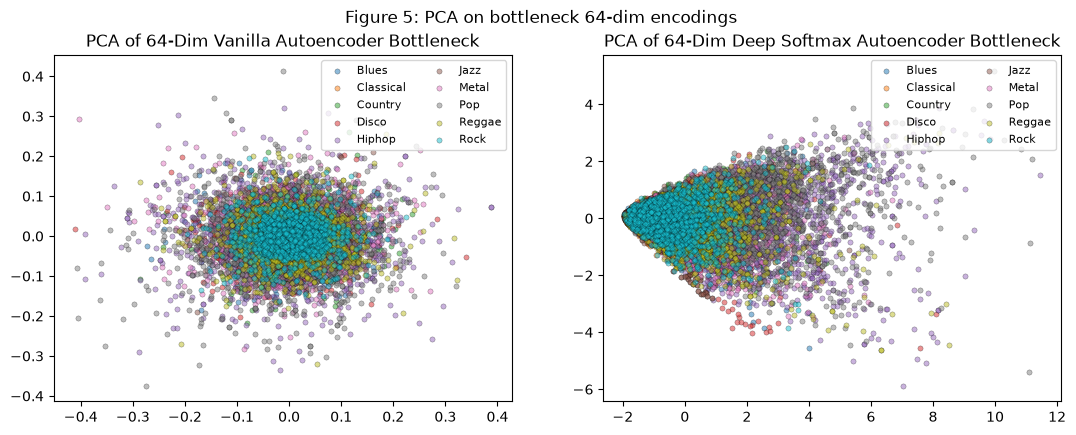

In [15]:
ALL = np.arange(len(X))
ae_out, dsae_out = predict(vanilla_ae, ALL), predict(deep_softmax_ae, ALL)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pca_plot(axes[0], ae_out["encoding"].numpy(), y, "PCA of 64-Dim Vanilla Autoencoder Bottleneck")
pca_plot(axes[1], dsae_out["encoding"].numpy(), y, "PCA of 64-Dim Deep Softmax Autoencoder Bottleneck")
fig.suptitle("Figure 5: PCA on bottleneck 64-dim encodings")
fig.savefig(OUT / "figure5_pca_bottleneck.png", dpi=150, bbox_inches="tight"); plt.show()

## Appendix — historical reference and robustness experiments

The paper's numbers below are **quoted from the PDF** (Table 1 p.3, Table 2 p.4), for its four-genre experiment.
They are displayed separately from the ten-genre results. Differences across these tasks cannot measure a
reproduction gap. The five-seed and alternative-setting experiments below all use the full ten-genre dataset.

In [16]:
# The published tables describe a different, four-genre task. Keep their labels independent.
PAPER_TABLE1 = pd.DataFrame([[.520, .381, .364], [.949, .641, .653]],
                          index=table1.index, columns=["Train (6,000)", "Dev (1,000)", "Test (1,000)"])
PAPER_TABLE2 = pd.DataFrame({"Precision": [.783, .606, .515, .670],
                           "Recall": [.775, .627, .554, .608],
                           "F1 Score": [.779, .616, .5337, .638]},
                          index=["Classical", "Jazz", "Metal", "Pop"])
print("Historical reference only: the paper evaluated four genres; these are not ten-genre baselines.")
display(PAPER_TABLE1.style.format("{:.1%}"))
display(PAPER_TABLE2.round(3))
print(f"Current {N_CLASSES}-genre results:")
display(table1.style.format("{:.1%}"))
display(table2.round(3))

Historical reference only: the paper evaluated four genres; these are not ten-genre baselines.


,"Train (6,000)","Dev (1,000)","Test (1,000)"
Two Layer Neural Network,52.0%,38.1%,36.4%
Deep Softmax Autoencoder,94.9%,64.1%,65.3%


,Precision,Recall,F1 Score
Classical,0.783,0.775,0.779
Jazz,0.606,0.627,0.616
Metal,0.515,0.554,0.534
Pop,0.670,0.608,0.638


Current 10-genre results:


,Train Set (15000 Examples),Dev Set (2500 Examples),Test Set (2500 Examples)
Two Layer Neural Network,28.4%,18.2%,17.5%
Deep Softmax Autoencoder,73.5%,28.0%,28.5%


,Precision,Recall,F1 Score
Blues,0.257,0.201,0.226
Classical,0.599,0.746,0.664
Country,0.164,0.154,0.159
Disco,0.231,0.199,0.214
Hiphop,0.240,0.282,0.259
Jazz,0.413,0.446,0.429
Metal,0.187,0.224,0.204
Pop,0.302,0.278,0.290
Reggae,0.233,0.174,0.199
Rock,0.138,0.157,0.147


### Variation across seeds

The next cell repeats the paper-model training schedules on the ten-genre dataset with five seeds.
Each seed draws a new 15,000 / 2,500 / 2,500 clip split and new initial weights.

In [17]:
SEEDS = [0, 1, 2, 3, 4]

def run(seed, model_class, loss_fn, epochs, sizes=SPLIT_SIZES):
    s = random_split(seed, sizes)
    model, _ = train("variant", model_class, loss_fn, epochs, seed=seed, data_split=s, save=False)
    return {part: accuracy(model, idx) for part, idx in s.items() if len(idx)}

start = time.time()
seed_runs = pd.DataFrame(
    [{"model": "Two Layer Neural Network", "seed": sd, **run(sd, TwoLayerNN, cross_entropy, EPOCHS["two_layer_nn"])}
     for sd in SEEDS] +
    [{"model": "Deep Softmax Autoencoder", "seed": sd, **run(sd, DeepSoftmaxAutoencoder, deep_softmax_loss,
                                                               EPOCHS["deep_softmax_ae"])} for sd in SEEDS])
print(f"{len(seed_runs)} runs in {time.time() - start:.0f} s")
display(seed_runs.pivot(index="seed", columns="model", values=["train", "dev", "test"]).style.format("{:.1%}"))
seed_summary = seed_runs.groupby("model")[["train", "dev", "test"]].agg(["mean", "std", "min", "max"])
display(seed_summary.style.format("{:.1%}"))

10 runs in 395 s


**2. The authors' code used different settings from the paper.** The linked code differs from the paper in four ways:
- its loss is `mean-over-500 MSE + 0.1·CE`, not Eq. 3;
- its keep probability is 0.8, not 0.9;
- the joint model trains for 200 epochs;
- it holds out a single 2,000-example dev set (a 6,000 / 2,000 split), and the test script evaluates on that set.

The next cell trains the Deep Softmax Autoencoder with those loss, dropout and epoch settings, using the same five seeds. The split is scaled to 15,000 / 5,000 for all ten genres.

In [18]:
def code_loss(out, x, t):            # authors' code: tf.reduce_mean((x - g(f(x)))^2) + 0.1 * mean CE
    return (x - out["reconstruction"]).pow(2).mean() + 0.1 * cross_entropy(out, x, t)

start = time.time()
code_runs = pd.DataFrame([{"seed": sd, **run(sd, lambda: DeepSoftmaxAutoencoder(dropout=0.2), code_loss, 200,
                                             sizes=CODE_SPLIT_SIZES)} for sd in SEEDS])
print(f"{len(code_runs)} runs in {time.time() - start:.0f} s")
display(code_runs.set_index("seed").style.format("{:.1%}"))
display(code_runs[["train", "dev"]].agg(["mean", "std", "min", "max"]).style.format("{:.1%}"))

5 runs in 127 s


,train,dev
seed,,
0,50.0%,28.3%
1,51.6%,27.9%
2,48.3%,27.1%
3,50.9%,28.1%
4,51.1%,27.5%


,train,dev
mean,50.4%,27.8%
std,1.3%,0.5%
min,48.3%,27.1%
max,51.6%,28.3%


**3. What the reconstruction term actually does.** Eq. 3 combines reconstruction and classification. The next cell
measures, for the trained Deep Softmax Autoencoder, the size of each weighted term and whether the decoder's
ReLU output is still active. If the decoder outputs only zeros, the reconstruction term is a constant. It then
sends no gradient, and the joint model trains as a classifier on top of the encoder.

In [19]:
tr = split["train"]
out = predict(deep_softmax_ae, tr)
recon_term = GAMMA * reconstruction(out, X_t[tr], y_t[tr]).item()
ce_term = (1 - GAMMA) * cross_entropy(out, X_t[tr], y_t[tr]).item()
print(f"0.9 x reconstruction = {recon_term:.4f} | 0.1 x cross-entropy = {ce_term:.4f}")
print("fraction of joint-model reconstruction values > 0:", (out["reconstruction"] > 0).float().mean().item())
print("0.9 x mean sum(x^2) over train:", GAMMA * float((X[tr] ** 2).sum(1).mean()))

0.9 x reconstruction = 5.5597 | 0.1 x cross-entropy = 0.0836
fraction of joint-model reconstruction values > 0: 0.0
0.9 x mean sum(x^2) over train: 5.559665679931641


**4. Summary.** The next table summarises the ten-genre results across the five seeds.
The alternative code settings use a 75% / 25% train/dev split, with no separate test set, and are shown separately.

In [20]:
rows = []
for model in table1.index:
    for part, col in zip(["train", "dev", "test"], table1.columns):
        s = seed_summary.loc[model, part]
        row = {"model": model, "split": part, "seed 0": table1.loc[model, col],
               "seeds mean": s["mean"], "seeds min": s["min"], "seeds max": s["max"]}
        rows.append(row)
summary = pd.DataFrame(rows).set_index(["model", "split"])
display(summary.style.format("{:.1%}"))
print("Authors' alternative settings: train/dev only (75% / 25%); no separate test set.")
display(code_runs[["train", "dev"]].agg(["mean", "std", "min", "max"]).style.format("{:.1%}"))

Authors' alternative settings: train/dev only (75% / 25%); no separate test set.


,train,dev
mean,50.4%,27.8%
std,1.3%,0.5%
min,48.3%,27.1%
max,51.6%,28.3%


### Reading the results

The tables above measure the same model architectures on all ten GTZAN genres. Use the seed ranges to assess
variation and the reconstruction diagnostics to inspect the unchanged decoder. The original paper evaluated
four genres, so its scores cannot establish a performance gap for this ten-class experiment.

Part 2 compares every model under the same ten-genre evaluation protocol.

In [21]:
results = {"genres": GENRES, "n_classes": N_CLASSES, "split_sizes": SPLIT_SIZES, "seed": SEED, "table1": table1.to_dict(), "table2": table2.to_dict(),
           "seed_runs": seed_runs.to_dict("records"), "code_settings_runs": code_runs.to_dict("records"),
           "confusion_matrix_test_normalized": cm.tolist(),
           "vanilla_ae_final": ae_history.iloc[-1].to_dict()}
(OUT / "results.json").write_text(json.dumps(results, indent=2, default=float))
print("Saved models, histories, figures and results to", OUT.relative_to(ROOT))

Saved models, histories, figures and results to artifacts/paper_reproduction/gtzan_10_genres


---
# Part 2 — Improving on the paper

Part 1 ran the paper's architectures on the full ten-genre dataset. Part 2 builds on that model to improve genre accuracy. Each step adds one change on
top of the previous step, so the gain from each change can be measured separately.

| Step | Model | What changes |
|---|---|---|
| 0 | Paper models (Part 1) | nothing; re-evaluated under the protocol below |
| 1 | Fixed Deep Softmax AE | linear decoder output (no dead ReLU), standardised input, reshuffle every epoch, keep the best-dev checkpoint, re-tuned γ |
| 2 | Fixed Deep Softmax AE, more signal | smaller pooling window and all 30 s of every song |
| 3 | **Convolutional Deep Softmax AE** (raw waveform) | 1-D convolutional encoder/decoder, same 64-dim bottleneck, softmax head and Eq. 3-style loss |
| 4 | Mel-spectrogram Deep Softmax AE (extra) | log-mel spectrogram input with a 2-D convolutional encoder/decoder; this drops the paper's "no feature engineering" premise |

**Evaluation protocol**
- **Two splits.** The *clip split* is a random 15,000 / 2,500 / 2,500 clip split, preserving the paper's proportions. The *song split* keeps every song, and any exact duplicate recordings, inside one
  partition, targeting 80 / 10 / 10 songs per genre (indivisible duplicate groups can shift counts slightly). It tests on songs the model has never heard.
- **Evaluation clips.** Dev and test always use the paper's clips (the first 20 segments of each song).
  Extra segments, where a step uses them, are added to the training set only.
- **Seeds.** Each final model runs with seeds 0–4 on both splits.
- **Metrics.** We report clip accuracy (train, dev, test), test macro-F1, and test song accuracy. Song accuracy
  averages the softmax outputs over all of a song's test clips and takes the top genre.
- **No tuning on test.** Every choice (γ, pooling, extra audio) is made by a sweep on the **dev** set of the clip
  split with seed 0, and the winning value is read from the sweep result in code. Test results are never used to
  choose anything.
- **Caching.** Trained models and results are cached in `artifacts/improvements/gtzan_10_genres/`. With `RETRAIN = False`, a
  re-run reloads the cache instead of retraining. Set `RETRAIN = True` to train everything from scratch.

In [22]:
from sklearn.metrics import f1_score
torch.use_deterministic_algorithms(True, warn_only=True)
RETRAIN = False
CACHE = ROOT / "artifacts/improvements" / DATASET_ID
CACHE.mkdir(parents=True, exist_ok=True)
SEEDS = [0, 1, 2, 3, 4]
SPLIT_KINDS = ["clip", "song"]
N_SONGS, PAPER_SEGS = len(songs), SEGMENTS_PER_SONG
ALL_SEGS = min(len(s["audio"]) for s in songs) // SEGMENT_SAMPLES       # segments that fit in every song
song_label = np.array([s["label"] for s in songs])
song_genre = np.array([s["genre"] for s in songs])
print(f"{ALL_SEGS} segments of {SEGMENT_SAMPLES} samples fit in every song; the paper uses {PAPER_SEGS}")

def waveform_segments(pool, n_segments):
    # (songs, segments, 20000 / pool): consecutive segments, average-pooled as in the paper
    out = np.empty((N_SONGS, n_segments, SEGMENT_SAMPLES // pool), np.float32)
    for k, s in enumerate(songs):
        out[k] = s["audio"][:n_segments * SEGMENT_SAMPLES].reshape(n_segments, -1, pool).mean(-1)
    return out

# Paper clip i (Part 1) is segment i % 20 of song i // 20
assert np.allclose(waveform_segments(POOL_SIZE, PAPER_SEGS).reshape(-1, 500), X)

33 segments of 20000 samples fit in every song; the paper uses 20


### Splits

A split maps each partition to `(song, segment)` pairs.
- The clip split reproduces Part 1's `random_split` exactly.
- The song split groups byte-identical recordings across all genres first, so a duplicate can never sit on both sides of the split.
  GTZAN has known exact duplicates. Near-duplicates, such as different excerpts of the same song, cannot be
  detected from the audio bytes, so they are not grouped.

In [23]:
audio_digest = np.array([hashlib.sha256(s["audio"].tobytes()).hexdigest() for s in songs])
print("songs sharing identical audio with another song:",
      int(sum((audio_digest == d).sum() > 1 for d in audio_digest)))

def song_partition(seed):
    rng = np.random.default_rng(seed)
    # Group globally: metal.00058 and rock.00016 contain identical audio with different labels.
    groups = {}
    for k, digest in enumerate(audio_digest):
        groups.setdefault(digest, []).append(k)
    groups = list(groups.values())
    names = np.array(["train", "dev", "test"])
    target = np.array([.8, .1, .1])[:, None] * np.bincount(song_label, minlength=N_CLASSES)
    counts = np.zeros_like(target)
    part = np.empty(N_SONGS, dtype=object)
    # Place larger groups first, shuffling ties, then fill the remaining per-genre quotas.
    order = sorted(rng.permutation(len(groups)), key=lambda i: -len(groups[i]))
    for i in order:
        group = groups[i]
        labels = np.bincount(song_label[group], minlength=N_CLASSES)
        remaining = target - counts
        fits = np.all(labels <= remaining, axis=1)
        score = (remaining[:, labels > 0] / target[:, labels > 0]).mean(axis=1)
        if fits.any():
            score[~fits] = -np.inf
        # A group is indivisible, so arbitrary datasets can differ slightly from the target quotas.
        chosen = int(rng.choice(np.flatnonzero(np.isclose(score, score.max()))))
        part[group] = names[chosen]
        counts[chosen] += labels
    return part

def make_split(kind, seed, extra_segments=False):
    if kind == "clip":
        parts = {p: np.stack([idx // PAPER_SEGS, idx % PAPER_SEGS], 1) for p, idx in random_split(seed).items()}
        extra_songs = np.arange(N_SONGS)
    elif kind == "song":
        part = song_partition(seed)
        parts = {p: np.array([(k, j) for k in np.flatnonzero(part == p) for j in range(PAPER_SEGS)])
                 for p in ["train", "dev", "test"]}
        extra_songs = np.flatnonzero(part == "train")
    else:
        raise ValueError(f"Unknown split kind: {kind}")
    if extra_segments:                        # extra audio is only ever added to the training set
        more = np.array([(k, j) for k in extra_songs for j in range(PAPER_SEGS, ALL_SEGS)])
        parts["train"] = np.concatenate([parts["train"], more])
    return parts

assert all(np.array_equal(make_split("clip", 0)[p][:, 0] * PAPER_SEGS + make_split("clip", 0)[p][:, 1], split[p])
           for p in split)
for seed in SEEDS:
    s = make_split("song", seed, extra_segments=True)
    songs_in = {p: set(v[:, 0]) for p, v in s.items()}
    assert set.union(*songs_in.values()) == set(range(N_SONGS))
    assert all(set(song_label[list(indices)]) == set(range(N_CLASSES)) for indices in songs_in.values())
    assert not (songs_in["train"] & songs_in["dev"] or songs_in["train"] & songs_in["test"] or songs_in["dev"] & songs_in["test"])
    assert all(len(set(audio_digest[list(songs_in[p])]) & set(audio_digest[list(songs_in[q])])) == 0
               for p in songs_in for q in songs_in if p < q)
s = make_split("song", 0)
print("song split, seed 0:", {p: f"{len(set(v[:, 0]))} songs / {len(v)} clips" for p, v in s.items()})
print("clip split, seed 0, test songs that also have training clips:",
      len(set(make_split("clip", 0)["test"][:, 0]) & set(make_split("clip", 0)["train"][:, 0])))

songs sharing identical audio with another song: 28
song split, seed 0: {'train': '800 songs / 16000 clips', 'dev': '100 songs / 2000 clips', 'test': '100 songs / 2000 clips'}
clip split, seed 0, test songs that also have training clips: 935


### Shared training and evaluation code

`fit_model` is used for all improved models (Steps 1–4). It differs from the paper's training loop in four ways:
- inputs are standardised with the training-set mean and standard deviation (one scalar each for waveforms,
  one per mel band for spectrograms);
- batches are reshuffled every epoch;
- dev accuracy is measured after each epoch, and the best epoch's weights are kept;
- training stops after `patience` epochs without a dev improvement.

`evaluate_model` computes the same metrics for every model, including the paper's.

In [24]:
def gather(data, pairs):
    return torch.from_numpy(data[pairs[:, 0], pairs[:, 1]])

def batched(model, inputs, size=500):
    model.eval()
    with torch.no_grad():
        outs = [model(inputs[i:i + size]) for i in range(0, len(inputs), size)]
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}

def dsae_loss(gamma):
    # Eq. 3 structure; reconstruction is averaged over input values so gamma means the same for every input size
    def loss(out, x, t):
        ce = nn.functional.cross_entropy(out["logits"], t)
        return ce if gamma == 0 else gamma * (x - out["reconstruction"]).pow(2).mean() + (1 - gamma) * ce
    return loss

def standardizer(train_inputs, per_band):
    dims = (0, 2) if per_band else None
    mu = train_inputs.mean(dim=dims, keepdim=True)[0] if per_band else train_inputs.mean()
    sd = train_inputs.std(dim=dims, keepdim=True)[0] if per_band else train_inputs.std()
    return lambda a: (a - mu) / sd

def fit_model(model, data, parts, loss_fn, max_epochs, lr, batch, patience, seed, per_band=False):
    seed_everything(seed)
    x_tr, y_tr = gather(data, parts["train"]), torch.from_numpy(song_label[parts["train"][:, 0]])
    x_dv, y_dv = gather(data, parts["dev"]), torch.from_numpy(song_label[parts["dev"][:, 0]])
    norm = standardizer(x_tr, per_band)
    x_tr, x_dv = norm(x_tr), norm(x_dv)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(seed)
    best_acc, best_state, best_epoch, history = -1.0, None, 0, []
    for epoch in range(1, max_epochs + 1):
        model.train()
        losses = []
        for b in torch.randperm(len(x_tr), generator=generator).split(batch):    # reshuffled every epoch
            loss = loss_fn(model(x_tr[b]), x_tr[b], y_tr[b])
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(loss.item())
        dev_acc = (batched(model, x_dv)["logits"].argmax(1) == y_dv).float().mean().item()
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "dev_accuracy": dev_acc})
        if epoch == 1 or epoch % 10 == 0 or epoch == max_epochs:
            print(f"  epoch {epoch:3d}: loss {np.mean(losses):.4f}, dev {dev_acc:.3f}", flush=True)
        if dev_acc > best_acc:
            best_acc, best_epoch = dev_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model, norm, pd.DataFrame(history), best_epoch

def evaluate_model(model, data, parts, norm):
    result = {}
    for p in ["train", "dev", "test"]:
        out = batched(model, norm(gather(data, parts[p])))
        true = song_label[parts[p][:, 0]]
        pred = out["logits"].argmax(1).numpy()
        result[f"{p}_accuracy"] = float((pred == true).mean())
        if p == "test":
            result["test_macro_f1"] = float(f1_score(true, pred, labels=range(N_CLASSES), average="macro", zero_division=0))
            probs = pd.DataFrame(torch.softmax(out["logits"], 1).numpy()).groupby(parts[p][:, 0]).mean()
            result["test_song_accuracy"] = float((probs.values.argmax(1) == song_label[probs.index]).mean())
            result["test_songs"] = len(probs)
    return result

### Experiment runner and cache

`run_experiment` trains one configuration (model, data, split kind, seed) and evaluates it. Results and weights
are cached under a key built from the experiment configuration, ordered genre labels, audio digest and preprocessing settings. Ten-genre artifacts use a separate directory, so four-genre weights and scores cannot be reused accidentally.

In [25]:
# The ordered labels, audio content and preprocessing are part of every cache key.
CACHE_CONTEXT = {"genres": GENRES, "n_classes": N_CLASSES, "sample_rate": SAMPLE_RATE,
                 "segment_samples": SEGMENT_SAMPLES, "paper_segments": PAPER_SEGS,
                 "all_segments": ALL_SEGS, "pool_size": POOL_SIZE, "split_sizes": SPLIT_SIZES,
                 "song_split": "global_audio_groups_v1", "model_version": 1,
                 "audio_sha256": hashlib.sha256("".join(audio_digest).encode()).hexdigest()}
(CACHE / "dataset_config.json").write_text(json.dumps(CACHE_CONTEXT, indent=2))
DATA = {}                                         # name -> array (songs, segments, ...)

def cache_key(cfg):
    return hashlib.sha256(json.dumps({"dataset": CACHE_CONTEXT, "experiment": cfg}, sort_keys=True).encode()).hexdigest()[:16]

def run_experiment(cfg, build, verbose=True):
    # cfg must contain: name, data, kind, seed, extra, gamma, max_epochs, lr, batch, patience
    key = cache_key(cfg)
    path = CACHE / f"{cfg['name']}_{key}"
    parts = make_split(cfg["kind"], cfg["seed"], cfg["extra"])
    data = DATA[cfg["data"]]
    if not RETRAIN and all(path.with_suffix(ext).exists() for ext in (".json", ".pt", ".csv")):
        result = json.loads(path.with_suffix(".json").read_text())
    else:
        print(f"Training {cfg['name']} | {cfg['kind']} | seed {cfg['seed']} | data {cfg['data']} | gamma {cfg['gamma']}", flush=True)
        start = time.time()
        model, norm, history, best_epoch = fit_model(
            build(), data, parts, dsae_loss(cfg["gamma"]), cfg["max_epochs"], cfg["lr"], cfg["batch"],
            cfg["patience"], cfg["seed"], per_band=cfg["data"].startswith("mel"))
        result = {**cfg, "dataset": CACHE_CONTEXT, **evaluate_model(model, data, parts, norm), "best_epoch": best_epoch,
                  "epochs_run": len(history), "seconds": round(time.time() - start, 1)}
        torch.save(model.state_dict(), path.with_suffix(".pt"))
        history.to_csv(path.with_suffix(".csv"), index=False)
        path.with_suffix(".json").write_text(json.dumps(result, indent=2))
    if verbose:
        print(f"{cfg['name']:>12s} {cfg['kind']:>4s} seed {cfg['seed']}: dev {result['dev_accuracy']:.3f} "
              f"test {result['test_accuracy']:.3f} song {result['test_song_accuracy']:.3f} "
              f"(best epoch {result['best_epoch']}, {result['seconds']} s)")
    return result

def load_experiment(cfg, build):
    # rebuild a trained model and its input standardiser from the cache
    path = CACHE / f"{cfg['name']}_{cache_key(cfg)}"
    model = build(); model.load_state_dict(torch.load(path.with_suffix(".pt"))); model.eval()
    parts = make_split(cfg["kind"], cfg["seed"], cfg["extra"])
    norm = standardizer(gather(DATA[cfg["data"]], parts["train"]), cfg["data"].startswith("mel"))
    return model, norm, parts

def sweep(base, field, values, build_for):
    rows = [run_experiment({**base, field: v, "kind": "clip", "seed": 0}, build_for(v)) for v in values]
    table = pd.DataFrame(rows)[[field, "dev_accuracy", "best_epoch", "seconds"]]
    best = table.loc[table.dev_accuracy.idxmax(), field]     # chosen on dev only
    display(table.style.format({"dev_accuracy": "{:.1%}"}))
    print(f"chosen {field} = {best} (highest dev accuracy)")
    return best.item() if hasattr(best, "item") else best

def run_all_seeds(cfg, build):
    return pd.DataFrame([run_experiment({**cfg, "kind": kind, "seed": seed}, build)
                         for kind in SPLIT_KINDS for seed in SEEDS])

def summarize(results):
    cols = ["train_accuracy", "dev_accuracy", "test_accuracy", "test_macro_f1", "test_song_accuracy"]
    table = results.groupby("kind")[cols].agg(["mean", "std"])
    display(table.style.format("{:.1%}"))
    return table

## Step 0 — The paper's models under the same protocol

The paper's two-layer NN and Deep Softmax AE are retrained with Part 1's code and training settings, with ten classifier outputs, for seeds 0–4
on both splits. They are then scored with `evaluate_model`, so their numbers compare directly with every later
step. The paper models use the raw pooled input with no standardisation, exactly as in Part 1.

In [26]:
DATA["pool40_paper"] = waveform_segments(POOL_SIZE, PAPER_SEGS)
identity = lambda a: a

def run_paper_model(name, model_class, loss_fn, epochs, kind, seed):
    cfg = {"name": name, "data": "pool40_paper", "kind": kind, "seed": seed, "extra": False, "paper_settings": True}
    path = CACHE / f"{name}_{cache_key(cfg)}"
    if not RETRAIN and path.with_suffix(".json").exists():
        return json.loads(path.with_suffix(".json").read_text())
    parts = make_split(kind, seed)
    x_index = {p: v[:, 0] * PAPER_SEGS + v[:, 1] for p, v in parts.items()}
    print(f"Training {name} | {kind} | seed {seed}", flush=True)
    start = time.time()
    model, _ = train(name, model_class, loss_fn, epochs, seed=seed, data_split=x_index, save=False)
    result = {**cfg, "dataset": CACHE_CONTEXT, **evaluate_model(model, DATA["pool40_paper"], parts, identity),
              "best_epoch": epochs, "seconds": round(time.time() - start, 1)}
    path.with_suffix(".json").write_text(json.dumps(result, indent=2))
    return result

paper_results = {
    "Paper two-layer NN": pd.DataFrame([run_paper_model("paper_nn", TwoLayerNN, cross_entropy, EPOCHS["two_layer_nn"], k, s)
                                        for k in SPLIT_KINDS for s in SEEDS]),
    "Paper Deep Softmax AE": pd.DataFrame([run_paper_model("paper_dsae", DeepSoftmaxAutoencoder, deep_softmax_loss,
                                                           EPOCHS["deep_softmax_ae"], k, s)
                                           for k in SPLIT_KINDS for s in SEEDS]),
}
for name, res in paper_results.items():
    print(name); summarize(res)

Training paper_nn | clip | seed 0


Training paper_nn | clip | seed 1


Training paper_nn | clip | seed 2


Training paper_nn | clip | seed 3


Training paper_nn | clip | seed 4


Training paper_nn | song | seed 0


... (12 outputs left out)

Training paper_dsae | song | seed 3


Training paper_dsae | song | seed 4


Paper two-layer NN


Paper Deep Softmax AE


## Step 1 — Fix the paper's Deep Softmax Autoencoder

Same input (500 pooled values from the first 20 segments) and the same hidden-layer widths and activations as the paper, with ten classifier outputs.
The changes:
- the decoder's output layer is linear, so it can produce negative amplitudes and cannot die;
- inputs are standardised;
- batches are reshuffled every epoch;
- the best-dev checkpoint is kept, with early stopping;
- γ is chosen on dev.

The optimiser stays as in the paper (Adam, learning rate 0.0001, batch size 512) so the effect of these fixes is
isolated. The reconstruction term is averaged over input values, and γ = 0 means a pure classifier.

In [27]:
class FixedDeepSoftmaxAE(nn.Module):
    # paper architecture (Fig. 2) with a linear decoder output
    def __init__(self, input_dim=500, dropout=DROPOUT):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 256), nn.Sigmoid(),
                                     nn.Linear(256, 192), nn.Tanh(), nn.Dropout(dropout),
                                     nn.Linear(192, 128), nn.ReLU(),
                                     nn.Linear(128, 64), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(64, 128), nn.Sigmoid(),
                                     nn.Linear(128, 192), nn.Sigmoid(), nn.Dropout(dropout),
                                     nn.Linear(192, 256), nn.ReLU(),
                                     nn.Linear(256, input_dim))
        self.classifier = nn.Sequential(nn.Linear(64, 32), nn.Tanh(), nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, N_CLASSES))
        self.apply(xavier)
    def forward(self, x):
        z = self.encoder(x)
        return {"encoding": z, "reconstruction": self.decoder(z), "logits": self.classifier(z)}

STEP1 = {"name": "step1", "data": "pool40_paper", "extra": False, "gamma": 0.9,
         "max_epochs": 500, "lr": LEARNING_RATE, "batch": BATCH_SIZE, "patience": 50}
STEP1["gamma"] = sweep(STEP1, "gamma", [0.9, 0.5, 0.1, 0.0], lambda g: FixedDeepSoftmaxAE)
step1_results = run_all_seeds(STEP1, FixedDeepSoftmaxAE)
summarize(step1_results);

Training step1 | clip | seed 0 | data pool40_paper | gamma 0.9


  epoch   1: loss 1.1666, dev 0.170


  epoch  10: loss 1.1147, dev 0.206


  epoch  20: loss 1.0942, dev 0.232


  epoch  30: loss 1.0824, dev 0.248


  epoch  40: loss 1.0659, dev 0.263


... (235 outputs left out)

  epoch 160: loss 0.6399, dev 0.285


  epoch 170: loss 0.6035, dev 0.276


  epoch 180: loss 0.5674, dev 0.282


       step1 song seed 4: dev 0.289 test 0.268 song 0.430 (best epoch 130, 21.9 s)


## Step 2 — Keep more of the signal

The paper averages every 40 samples, which leaves an effective sample rate of about 551 Hz and keeps only content
below about 275 Hz. It also uses only the first 20 segments (about 18 s) of each 30-s song. Step 2 tries:
- a smaller pooling window, which gives a wider input layer and the same hidden widths;
- adding the remaining segments of every training song to the training set.

Both choices are swept on dev, with Step 1's γ.

In [28]:
for pool in [40, 20, 10]:
    DATA[f"pool{pool}_all"] = waveform_segments(pool, ALL_SEGS)
STEP2 = {**STEP1, "name": "step2"}
STEP2["data"] = sweep({**STEP2, "extra": False}, "data", ["pool40_all", "pool20_all", "pool10_all"],
                      lambda d: (lambda: FixedDeepSoftmaxAE(DATA[d].shape[-1])))
STEP2["extra"] = sweep(STEP2, "extra", [False, True],
                       lambda e: (lambda: FixedDeepSoftmaxAE(DATA[STEP2["data"]].shape[-1])))
step2_build = lambda: FixedDeepSoftmaxAE(DATA[STEP2["data"]].shape[-1])
step2_results = run_all_seeds(STEP2, step2_build)
summarize(step2_results);

Training step2 | clip | seed 0 | data pool40_all | gamma 0.1


  epoch   1: loss 2.1939, dev 0.134


  epoch  10: loss 2.0198, dev 0.220


  epoch  20: loss 1.8431, dev 0.243


  epoch  30: loss 1.7449, dev 0.240


  epoch  40: loss 1.6603, dev 0.260


... (222 outputs left out)

  epoch  90: loss 1.0667, dev 0.303


  epoch 100: loss 1.0000, dev 0.303


  epoch 110: loss 0.9397, dev 0.303


       step2 song seed 4: dev 0.308 test 0.285 song 0.380 (best epoch 68, 26.6 s)


## Step 3 — Convolutional Deep Softmax Autoencoder (raw waveform)

This is the paper's hybrid idea with a convolutional encoder and decoder. Convolutions detect the same pattern
(an onset, a note, a drum hit) wherever it occurs in the clip. A fully connected layer has to learn every position
separately. The model still works on the raw (average-pooled) waveform, so there is no feature engineering.

- **Encoder:** four 1-D convolution blocks (kernel 9, stride 4; 16 → 32 → 64 → 128 channels; batch norm; ReLU).
  Then global average- and max-pooling over time, and a linear layer to the **64-dim encoding**.
- **Decoder:** a linear layer back to a short feature map, then four transposed convolutions that rebuild the waveform.
- **Classifier head:** 64 → 32 → 16 → 10; only the output count expands.
- **Loss:** γ·reconstruction + (1 − γ)·cross-entropy.
- **Optimiser:** Adam, learning rate 0.001, batch size 64. Up to 40 epochs; early stopping after 8 epochs
  without a dev improvement.

The input pooling (8 or 4, giving 2,756 Hz or 5,512 Hz) and γ are swept on dev. Step 2's finding on extra segments
carries over.

In [ ]:
def conv_block(c_in, c_out):
    return [nn.Conv1d(c_in, c_out, 9, 4, 4), nn.BatchNorm1d(c_out), nn.ReLU()]

def deconv_block(c_in, c_out, last=False):
    layers = [nn.ConvTranspose1d(c_in, c_out, 8, 4, 2)]
    return layers if last else layers + [nn.BatchNorm1d(c_out), nn.ReLU()]

class ConvDeepSoftmaxAE(nn.Module):
    def __init__(self, length, dropout=DROPOUT):
        super().__init__()
        self.length, self.steps = length, length
        for _ in range(4):
            self.steps = (self.steps + 3) // 4
        self.features = nn.Sequential(*conv_block(1, 16), *conv_block(16, 32), *conv_block(32, 64), *conv_block(64, 128))
        self.to_encoding = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, 64), nn.ReLU())
        self.from_encoding = nn.Linear(64, 128 * self.steps)
        self.decoder = nn.Sequential(*deconv_block(128, 64), *deconv_block(64, 32), *deconv_block(32, 16),
                                     *deconv_block(16, 1, last=True))
        self.classifier = nn.Sequential(nn.Linear(64, 32), nn.Tanh(), nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, N_CLASSES))
    def forward(self, x):
        h = self.features(x.unsqueeze(1))
        z = self.to_encoding(torch.cat([h.mean(-1), h.amax(-1)], 1))
        r = self.decoder(self.from_encoding(z).view(-1, 128, self.steps))[:, 0, :self.length]
        return {"encoding": z, "reconstruction": r, "logits": self.classifier(z)}

for pool in [8, 4]:
    DATA[f"pool{pool}_all"] = waveform_segments(pool, ALL_SEGS)
STEP3 = {"name": "step3", "data": "pool8_all", "extra": STEP2["extra"], "gamma": 0.0,
         "max_epochs": 40, "lr": 1e-3, "batch": 64, "patience": 8}
step3_build = lambda d: (lambda: ConvDeepSoftmaxAE(DATA[d].shape[-1]))
STEP3["data"] = sweep(STEP3, "data", ["pool8_all", "pool4_all"], step3_build)
STEP3["gamma"] = sweep(STEP3, "gamma", [0.0, 0.1, 0.5], lambda g: step3_build(STEP3["data"]))
step3_results = run_all_seeds(STEP3, step3_build(STEP3["data"]))
summarize(step3_results);

## Step 4 — Mel-spectrogram Deep Softmax Autoencoder (extra)

This is the direction the paper names as future work (§6): feature engineering. Each 20,000-sample segment
becomes a log-mel spectrogram, computed with LibROSA (64 mel bands, FFT size 1,024, hop 512 → 64 × 40).
A 2-D convolutional Deep Softmax AE then learns from it. The structure matches Step 3:
- **Encoder:** four convolution blocks with 2 × 2 max-pooling, then global average + max pooling, giving the
  64-dim encoding.
- **Decoder:** transposed convolutions that rebuild the spectrogram.
- **Head:** 64 → 32 → 16 → 10.

Inputs are standardised per mel band. γ is swept on dev; training uses the same settings as Step 3.

In [ ]:
def mel_segments(n_segments):
    out = []
    for s in songs:
        frames = s["audio"][:n_segments * SEGMENT_SAMPLES].reshape(n_segments, SEGMENT_SAMPLES)
        mel = librosa.feature.melspectrogram(y=frames, sr=SAMPLE_RATE, n_fft=1024, hop_length=512, n_mels=64)
        out.append(librosa.power_to_db(mel))
    return np.stack(out).astype(np.float32)          # (songs, segments, 64, 40)

DATA["mel_all"] = mel_segments(ALL_SEGS)
print("mel spectrograms:", DATA["mel_all"].shape)

def conv2d_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, 1, 1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]

def deconv2d_block(c_in, c_out, last=False):
    layers = [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1)]
    return layers if last else layers + [nn.BatchNorm2d(c_out), nn.ReLU()]

class MelDeepSoftmaxAE(nn.Module):
    def __init__(self, shape, dropout=DROPOUT):
        super().__init__()
        self.shape = shape
        self.h, self.w = shape[0] // 16, -(-shape[1] // 16)
        self.features = nn.Sequential(*conv2d_block(1, 16), *conv2d_block(16, 32), *conv2d_block(32, 64),
                                      *conv2d_block(64, 128))
        self.to_encoding = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, 64), nn.ReLU())
        self.from_encoding = nn.Linear(64, 128 * self.h * self.w)
        self.decoder = nn.Sequential(*deconv2d_block(128, 64), *deconv2d_block(64, 32), *deconv2d_block(32, 16),
                                     *deconv2d_block(16, 1, last=True))
        self.classifier = nn.Sequential(nn.Linear(64, 32), nn.Tanh(), nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, N_CLASSES))
    def forward(self, x):
        h = self.features(x.unsqueeze(1))
        z = self.to_encoding(torch.cat([h.mean((2, 3)), h.amax((2, 3))], 1))
        r = self.decoder(self.from_encoding(z).view(-1, 128, self.h, self.w))[:, 0, :self.shape[0], :self.shape[1]]
        return {"encoding": z, "reconstruction": r, "logits": self.classifier(z)}

STEP4 = {**STEP3, "name": "step4", "data": "mel_all", "gamma": 0.0}
step4_build = lambda: MelDeepSoftmaxAE(DATA["mel_all"].shape[-2:])
STEP4["gamma"] = sweep(STEP4, "gamma", [0.0, 0.1, 0.5], lambda g: step4_build)
step4_results = run_all_seeds(STEP4, step4_build)
summarize(step4_results);

## Final comparison

One table covers every model on all ten genres and both splits. Each value is the mean ± standard deviation
over seeds 0–4. Every row is computed above. The paper's quoted four-genre scores are kept in the historical
appendix and are excluded from this comparison.

In [ ]:
all_results = {**paper_results,
               "Step 1: fixed Deep Softmax AE": step1_results,
               "Step 2: + more signal": step2_results,
               "Step 3: Conv Deep Softmax AE (raw audio)": step3_results,
               "Step 4: Mel Deep Softmax AE (extra)": step4_results}
METRICS = {"train_accuracy": "train acc", "dev_accuracy": "dev acc", "test_accuracy": "test acc",
           "test_macro_f1": "test macro-F1", "test_song_accuracy": "test song acc"}

def mean_std(values):
    return f"{values.mean():.1%} ± {values.std():.1%}"

rows = []  # Compare only models evaluated on this same ten-genre task.
for name, res in all_results.items():
    for kind in SPLIT_KINDS:
        sub = res[res.kind == kind]
        rows.append({"model": name, "split": kind, **{label: mean_std(sub[m]) for m, label in METRICS.items()}})
comparison = pd.DataFrame(rows).set_index(["split", "model"]).sort_index(level=0, sort_remaining=False).fillna("—")
display(comparison)
comparison.to_csv(CACHE / "comparison.csv")
pd.concat([r.assign(model=name) for name, r in all_results.items()], ignore_index=True).drop(columns="dataset").to_csv(
    CACHE / "all_results.csv", index=False)

mean_test = pd.DataFrame({name: res.groupby("kind").test_accuracy.mean() for name, res in all_results.items()}).T
fig, ax = plt.subplots(figsize=(10, 4))
mean_test.plot.barh(ax=ax, xerr=pd.DataFrame({n: r.groupby("kind").test_accuracy.std()
                                              for n, r in all_results.items()}).T, capsize=3)
ax.set(xlabel="test clip accuracy (mean ± std, 5 seeds)", xlim=(0, 1)); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.invert_yaxis()
fig.savefig(CACHE / "comparison_test_accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

## Best model — the paper's tables and figures

The best model is picked by **mean dev accuracy on the clip split**, never by test. The cell below recreates the
paper's evaluation for it on clip split seed 0:
- Table 1-style accuracies and Table 2 per-genre precision, recall and F1 on the test set;
- the normalised confusion matrix (Fig. 4);
- PCA of the 64-dim encodings (Fig. 5) and the 10-dim logits (Fig. 6), over all 20,000 evaluation clips.

In [ ]:
improved = {"Step 1: fixed Deep Softmax AE": (STEP1, FixedDeepSoftmaxAE),
            "Step 2: + more signal": (STEP2, step2_build),
            "Step 3: Conv Deep Softmax AE (raw audio)": (STEP3, step3_build(STEP3["data"])),
            "Step 4: Mel Deep Softmax AE (extra)": (STEP4, step4_build)}
dev_means = {name: all_results[name].query("kind == 'clip'").dev_accuracy.mean() for name in improved}
BEST = max(dev_means, key=dev_means.get)
best_cfg, best_build = improved[BEST]
print("best model by mean clip-split dev accuracy:", BEST, f"({dev_means[BEST]:.1%})")

best_model, best_norm, best_parts = load_experiment({**best_cfg, "kind": "clip", "seed": 0}, best_build)
data = DATA[best_cfg["data"]]
acc = {p: (batched(best_model, best_norm(gather(data, best_parts[p])))["logits"].argmax(1).numpy()
           == song_label[best_parts[p][:, 0]]).mean() for p in ["train", "dev", "test"]}
display(pd.DataFrame([acc], index=[BEST]).style.format("{:.1%}"))

test_out = batched(best_model, best_norm(gather(data, best_parts["test"])))
best_pred, best_true = test_out["logits"].argmax(1).numpy(), song_label[best_parts["test"][:, 0]]
p, r, f, _ = precision_recall_fscore_support(best_true, best_pred, labels=range(N_CLASSES), zero_division=0)
display(pd.DataFrame({"Precision": p, "Recall": r, "F1 Score": f}, index=[g.capitalize() for g in GENRES]).round(3))

cm_best = confusion_matrix(best_true, best_pred, labels=range(N_CLASSES)).astype(float)
cm_best /= cm_best.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_best, cmap=plt.cm.Blues); fig.colorbar(im, ax=ax)
ax.set(xticks=range(N_CLASSES), yticks=range(N_CLASSES), xticklabels=GENRES, yticklabels=GENRES, xlabel="Predicted label",
       ylabel="True label", title=f"Normalized Confusion Matrix over Test Set\n{BEST}")
plt.setp(ax.get_xticklabels(), rotation=45)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{cm_best[i, j]:.2f}", ha="center", color="white" if cm_best[i, j] > cm_best.max() / 2 else "black")
fig.savefig(CACHE / "best_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

paper_clips = np.array([(k, j) for k in range(N_SONGS) for j in range(PAPER_SEGS)])
all_out = batched(best_model, best_norm(gather(data, paper_clips)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pca_plot(axes[0], all_out["encoding"].numpy(), y, f"PCA of 64-Dim Encoding — {BEST}")
pca_plot(axes[1], all_out["logits"].numpy(), y, f"PCA of {N_CLASSES}-Dim Logits — {BEST}")
fig.savefig(CACHE / "best_pca.png", dpi=150, bbox_inches="tight"); plt.show()

## Demo — classify a held-out clip

The cell picks one test clip from the best model's split, plays the original audio and shows the predicted genre
probabilities. Change `DEMO_INDEX` to try another clip.

In [ ]:
from IPython.display import Audio
DEMO_INDEX = 0
k, j = best_parts["test"][DEMO_INDEX]
probs = torch.softmax(batched(best_model, best_norm(gather(data, best_parts["test"][[DEMO_INDEX]])))["logits"], 1)[0]
print(f"clip: {songs[k]['song']} segment {j}  |  true genre: {songs[k]['genre']}  |  "
      f"predicted: {GENRES[int(probs.argmax())]}")
display(pd.Series(probs.numpy(), index=GENRES).round(3).to_frame("probability"))
display(Audio(songs[k]["audio"][j * SEGMENT_SAMPLES:(j + 1) * SEGMENT_SAMPLES], rate=SAMPLE_RATE))